# Exercise 1 -- Know Your Data
## Exploring Wearable Sensor Data

**Course: Introduction to ML for IoT Systems**

---

### Before you start

This exercise has **three types of cells**:

| Symbol | Means |
|---|---|
| ✏️ **YOUR TURN** | You write the code |
| 🔧 **TWEAK IT** | Code is written -- you change a value and see what happens |
| 💬 **THINK** | Answer a question in the comment space |

**Run every cell in order, even the ones already written for you.**

---

### The story so far

You are working with data from a wearable fitness band worn by 10 volunteers.
The band recorded six different activities:
🚶 Walking &nbsp; 🏃 Running &nbsp; 🪑 Sitting &nbsp; 🧍 Standing &nbsp; 🚴 Cycling &nbsp; 🪜 Stairs

Each row in the dataset is one moment of sensor recording.
Your job in this exercise: **get to know the data before touching any model.**

> 💡 *In real ML projects, data exploration is not optional. Skipping it is
> the #1 reason models fail in production.*

---

## Step 0 -- Setup

Run this cell first. It loads the tools we need.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.figsize'] = (10, 4)
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:.3f}'.format)

print('Tools loaded! Ready to explore.')

Tools loaded! Ready to explore.


---
## Part 1 -- Loading the Data

The data lives in a file called `har_wearable_data.csv`.
CSV stands for **Comma-Separated Values** -- it is just a text file where
each row is one observation and commas separate the columns.

We use **pandas** to load it into a **DataFrame** -- think of it as a spreadsheet in Python.

### ✏️ YOUR TURN -- Load the file

Fill in the blank to load the CSV file.

```python
pd.read_csv('filename_here.csv')
```

In [ ]:
# Load the dataset -- fill in the filename
df = pd.read_csv('har_wearable_data-1.csv')

# Print the number of rows and columns
print(f'Rows: {df.shape[0]}')
print(f'Columns: {df.shape[1]}')

Rows: 2100
Columns: 10


### ✏️ YOUR TURN -- Preview the data

`.head()` shows the first few rows. Try it!

In [3]:
# Show the first 5 rows
df.head()

,subject_id,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z,heart_rate_bpm,skin_temp_c,activity
0,3,0.094,0.076,9.898,NaN,0.020,NaN,59.500,34.830,Sitting
1,3,NaN,-0.024,9.986,-0.001,-0.048,-0.030,83.800,33.460,Standing
2,8,1.956,0.142,NaN,0.154,0.297,-0.188,69.900,NaN,Walking
3,9,0.283,0.063,9.852,-0.016,0.007,0.071,51.400,34.040,Standing
4,9,0.474,0.220,10.311,7.908,-1.085,1.046,193.200,35.270,Running


In [12]:
# This cell is done for you -- just run it and read the output
# .info() is like an X-ray of your dataset
# It shows: column names, data types, and how many values are NOT missing
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2100 entries, 0 to 2099
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   subject_id      2100 non-null   int64  
 1   acc_x           2016 non-null   float64
 2   acc_y           2016 non-null   float64
 3   acc_z           2016 non-null   float64
 4   gyro_x          2016 non-null   float64
 5   gyro_y          2016 non-null   float64
 6   gyro_z          2016 non-null   float64
 7   heart_rate_bpm  2016 non-null   float64
 8   skin_temp_c     2016 non-null   float64
 9   activity        2100 non-null   str    
dtypes: float64(8), int64(1), str(1)
memory usage: 164.2 KB


### 💬 THINK -- Answer in the comment below

Look at the `.info()` output above and answer:
- How many columns have missing data?
- What type of data is the `activity` column? (number or text?)
- What does `non-null count` mean?

In [ ]:
# YOUR ANSWERS (replace the ... with your answers):
# Columns with missing data: columns 1-8 are missing data
# activity column type: text
# non-null count means: the count of those rows having data


---
## Part 2 -- Summary Statistics

Before plotting anything, `.describe()` gives you a quick numerical summary
of every column. It is the fastest way to spot suspicious values.

| Stat | What it tells you |
|---|---|
| `mean` | Average value |
| `std` | Spread -- how much values vary |
| `min` / `max` | Extreme values -- are they physically possible? |
| `50%` | Median (middle value) |

In [ ]:
# Run this -- read each row carefully
df.describe()

,subject_id,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z,heart_rate_bpm,skin_temp_c
count,2100.000,2016.000,2016.000,2016.000,2016.000,2016.000,2016.000,2016.000,2016.000
mean,5.434,0.128,0.006,9.818,0.238,0.122,0.118,102.368,34.528
std,2.881,2.338,1.077,1.963,1.366,0.758,0.655,35.467,0.519
min,1.000,-10.535,-6.579,0.089,-7.115,-3.705,-2.990,40.100,32.680
25%,3.000,-0.641,-0.358,9.216,-0.119,-0.103,-0.089,70.900,34.170
50%,5.000,0.025,0.013,9.820,0.045,0.027,0.030,95.650,34.520
75%,8.000,0.795,0.393,10.537,0.705,0.405,0.345,129.100,34.880
max,10.000,12.380,5.941,19.420,8.232,5.139,5.063,204.800,36.160


### 💬 THINK -- Sanity checks

> 💡 **Physics check**: `acc_z` should average close to **9.81 m/s²**
> because gravity always pulls downward on the wrist sensor.
> Heart rate should stay between **40 bpm** (sleep) and **220 bpm** (max sprint).

Look at the `describe()` output and answer:

In [ ]:
# What is the average acc_z? Is it close to 9.81? Its 9.818 which is close to 9.81
# What is the minimum heart_rate_bpm? Does it look reasonable? the minimum was 40.1 bpm which is very low is the person is awake but asleep is pretty normal.
# Which sensor has the largest std (most variable)? heart rate with 35.467
# Why might heart_rate_bpm vary so much across rows? The person can be either awake or sleeping or exercising and your heart rate varies significantly within those activities.

---
## Part 3 -- How Many Samples per Activity?

In ML we call the thing we want to predict the **label** or **class**.
Here, the label is the `activity` column.

**Class balance matters!** If we had 1000 Running samples and only 10 Sitting samples,
the model would mostly learn Running and ignore Sitting. We want balanced data.

### ✏️ YOUR TURN -- Count activities

`.value_counts()` counts how many times each unique value appears.
Use it on the `activity` column.

In [14]:
# Count how many samples exist for each activity
# Hint: df['column_name'].value_counts()
counts = df['activity'].value_counts()
print(counts)

activity
Sitting     350
Standing    350
Walking     350
Running     350
Stairs      350
Cycling     350
Name: count, dtype: int64


### 🔧 TWEAK IT -- Change the bar colour

The chart below is complete. Find the line with `color=` and change it.
Try: `'tomato'`, `'seagreen'`, `'mediumpurple'`, `'darkorange'`

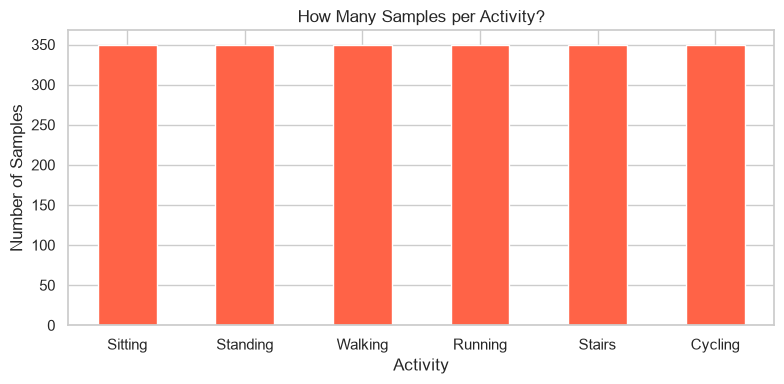

In [ ]:
plt.figure(figsize=(8, 4))
counts.plot(kind='bar',
            color='tomato',   # <- CHANGE THIS COLOUR
            edgecolor='white',
            rot=0)
plt.xlabel('Activity')
plt.ylabel('Number of Samples')
plt.title('How Many Samples per Activity?')
plt.tight_layout()
plt.show()

# Is this dataset balanced? (Yes/No and why)
# YOUR ANSWER: Yes, because there is an equal about of samples taken per activity

---
## Part 4 -- Finding Missing Data

IoT sensors are not perfect. Bluetooth drops, batteries die, sensors glitch.
The result: **missing values** -- gaps in the data shown as `NaN` (Not a Number).

**Why does this matter?** Most ML models crash if you feed them NaN.
You have to deal with missing data before modeling.

### Step 1: Find the missing values

In [15]:
# .isnull() marks every missing cell as True
# .sum() counts the Trues per column
missing = df.isnull().sum()
print('Missing values per column:')
print(missing)

# What percentage of each column is missing?
missing_pct = (missing / len(df) * 100).round(1)
print('\nAs a percentage:')
print(missing_pct[missing_pct > 0])

Missing values per column:
subject_id         0
acc_x             84
acc_y             84
acc_z             84
gyro_x            84
gyro_y            84
gyro_z            84
heart_rate_bpm    84
skin_temp_c       84
activity           0
dtype: int64

As a percentage:
acc_x            4.000
acc_y            4.000
acc_z            4.000
gyro_x           4.000
gyro_y           4.000
gyro_z           4.000
heart_rate_bpm   4.000
skin_temp_c      4.000
dtype: float64


### 🔧 TWEAK IT -- Visualise missing data

Run the cell and look at the pattern. Then try changing `cmap='viridis'` to
`cmap='YlOrRd'` or `cmap='coolwarm'` -- which do you find clearest?

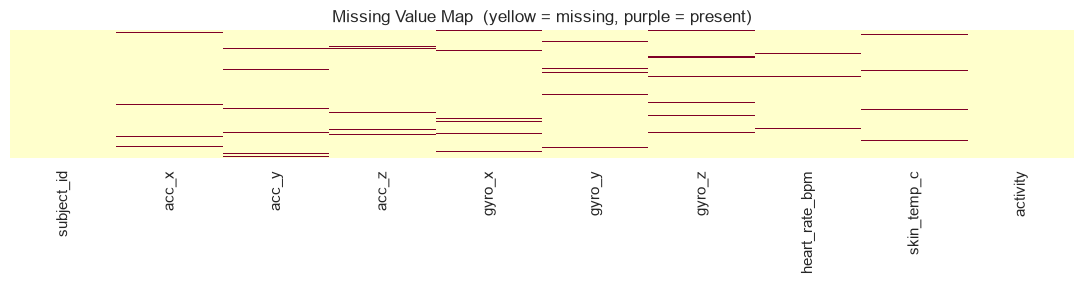

In [ ]:
plt.figure(figsize=(11, 3))
sns.heatmap(df.isnull(),
            cbar=False,
            yticklabels=False,
            cmap='YlOrRd')   # <- TRY CHANGING THIS
plt.title('Missing Value Map  (yellow = missing, purple = present)')
plt.tight_layout()
plt.show()

# Does the missing data look random, or does it cluster in certain rows?
# YOUR ANSWER: It looks random.

### Step 2: Fix the missing values

The simplest and most common fix is **median imputation**:
replace each missing value with the **median** of that column.

**Why median, not mean?**
Imagine heart rate data: most readings are 70-90 bpm but one reading was 210 bpm
(maybe the sensor glitched). The **mean** gets pulled up by that spike.
The **median** ignores it and stays near 80. It is more robust.

```
Data:   70, 75, 80, 82, 210
Mean:   103  <- pulled up by the spike!
Median:  80  <- stable, ignores the spike
```

### ✏️ YOUR TURN -- Fix the missing values

In [17]:
sensor_cols = ['acc_x','acc_y','acc_z','gyro_x','gyro_y','gyro_z',
               'heart_rate_bpm','skin_temp_c']

# Step 1: compute the median of each sensor column
# Hint: df[sensor_cols].median()
medians = df[sensor_cols].median()
print('Medians we will use:')
print(medians.round(3))

# Step 2: fill missing values with those medians
# Hint: df[sensor_cols].fillna(medians)
df[sensor_cols] = df[sensor_cols].fillna(medians)

# Check: how many missing values remain?
print(f'\nMissing values remaining: {df.isnull().sum().sum()}')
print('All fixed!' if df.isnull().sum().sum() == 0 else 'Hmm, something is still missing.')

Medians we will use:
acc_x             0.025
acc_y             0.013
acc_z             9.820
gyro_x            0.045
gyro_y            0.027
gyro_z            0.030
heart_rate_bpm   95.650
skin_temp_c      34.520
dtype: float64

Missing values remaining: 0
All fixed!


---
## Part 5 -- Visualising the Data

Numbers alone only tell part of the story. **Visualisation** reveals patterns,
outliers, and structure that summary statistics can miss.

We will look at **histograms** -- they show the shape of your data:
how values are distributed across their range.

The key question we are asking: **do different activities produce different sensor patterns?**
If yes, a model can learn to tell them apart.

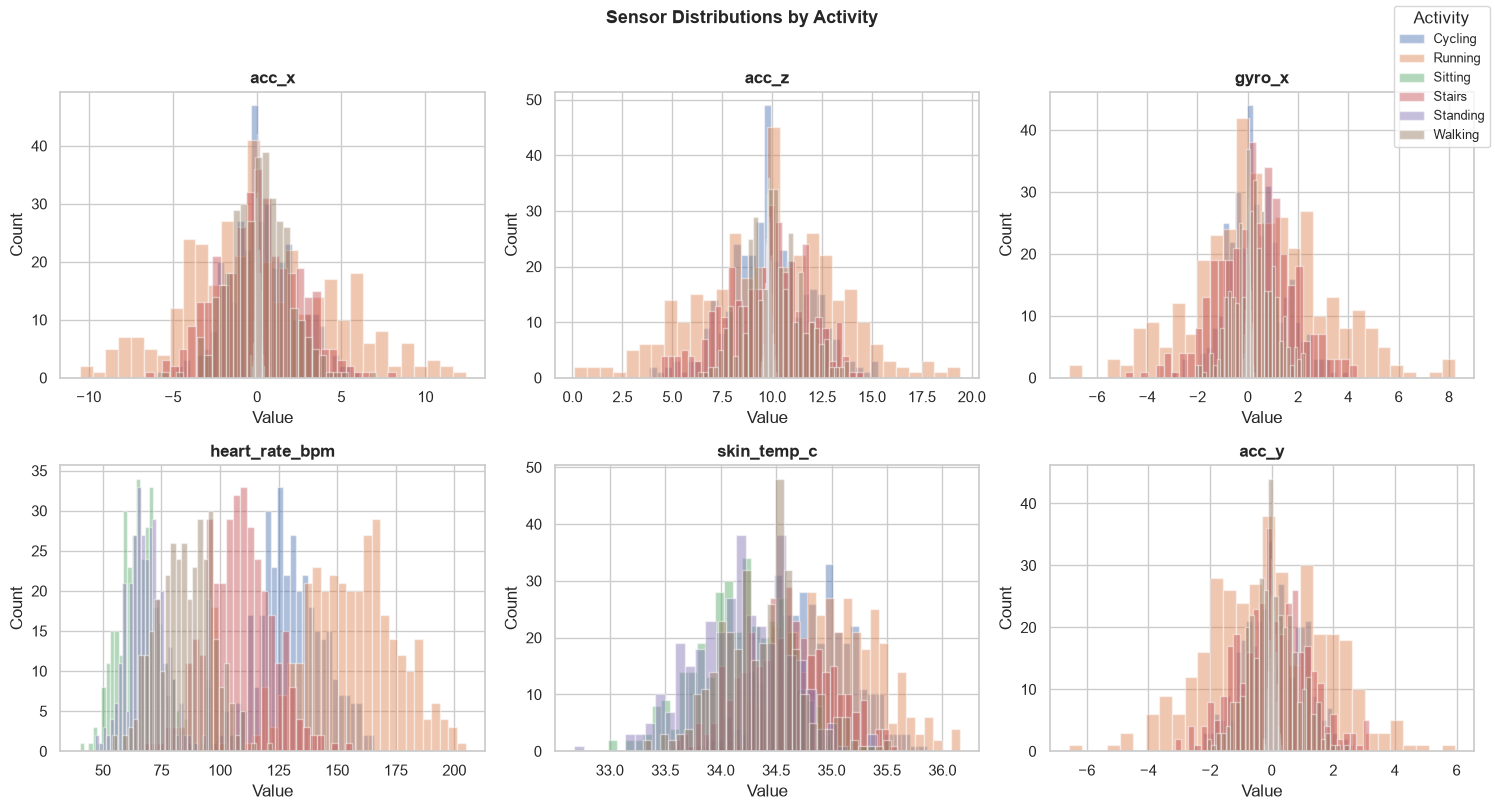

In [18]:
# This chart overlays histograms for each activity on the same axis
# If the humps SEPARATE well, the sensor is useful for recognition
# If they all overlap, the sensor is not very informative alone

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sensors = ['acc_x','acc_z','gyro_x','heart_rate_bpm','skin_temp_c','acc_y']
activities = sorted(df['activity'].unique())

for ax, sensor in zip(axes.flatten(), sensors):
    for act in activities:
        data = df[df['activity'] == act][sensor]
        ax.hist(data, bins=30, alpha=0.45, label=act)
    ax.set_title(sensor, fontweight='bold')
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')

handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', fontsize=9, title='Activity')
plt.suptitle('Sensor Distributions by Activity', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 💬 THINK -- Read the histograms

Look at the six charts and answer:

In [ ]:
# YOUR ANSWERS:
# Which sensor separates activities the BEST? (activities barely overlap) heart_rate_bpm
# Which sensor separates activities the WORST? (activities all overlap) acc_x
# Running vs Sitting -- which sensor makes them easiest to tell apart? heart_rate_bpm
# Why might acc_z be a good signal? (hint: think about gravity) theres is a constant pull for gravity to compare against which is going to give very consistant results.

### 🔧 TWEAK IT -- Zoom in on one sensor

The chart below shows just ONE sensor at a time.
**Change `SENSOR_TO_PLOT`** to explore different sensors.

Try: `'heart_rate_bpm'`, `'acc_z'`, `'gyro_x'`, `'skin_temp_c'`

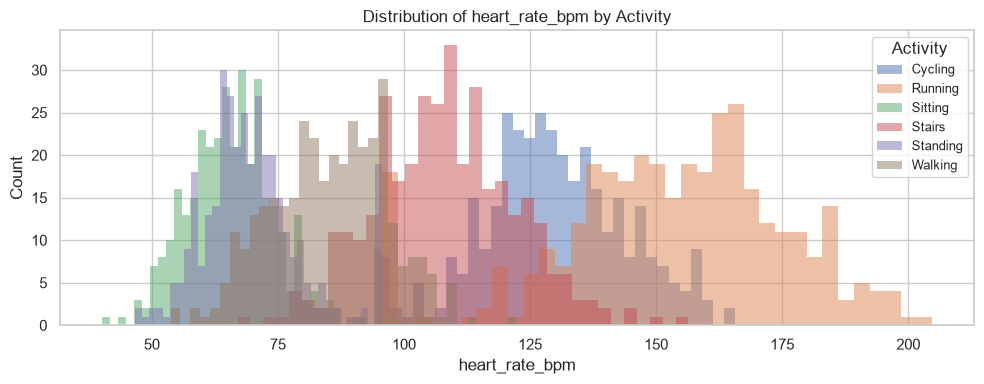

In [ ]:
SENSOR_TO_PLOT = 'heart_rate_bpm'   # <- CHANGE THIS

plt.figure(figsize=(10, 4))
for act in sorted(df['activity'].unique()):
    data = df[df['activity'] == act][SENSOR_TO_PLOT]
    plt.hist(data, bins=35, alpha=0.5, label=act, edgecolor='none')

plt.xlabel(SENSOR_TO_PLOT)
plt.ylabel('Count')
plt.title(f'Distribution of {SENSOR_TO_PLOT} by Activity')
plt.legend(title='Activity', fontsize=9)
plt.tight_layout()
plt.show()

# After exploring: which sensor is your personal favourite for separating activities?
# YOUR ANSWER: heart rate bpm because you can see each activity clearly and see the diffrences well.

---
## Part 6 -- Averages by Activity

Histograms show shape. Sometimes we just want a simple table:
**what is the average sensor value for each activity?**

This is called a **group-by** operation:
split the data by activity, then compute a statistic for each group.

### ✏️ YOUR TURN -- Compute group averages

In [25]:
# Group the data by 'activity' and compute the mean of key sensors
# Hint: df.groupby('column')[list_of_columns].mean()

key_sensors = ['heart_rate_bpm', 'skin_temp_c', 'acc_z']

group_means = df.groupby('activity')[key_sensors].mean()


# Sort by heart rate so the table is easy to read
print(group_means.sort_values('heart_rate_bpm').round(2))

          heart_rate_bpm  skin_temp_c  acc_z
activity                                    
Sitting           66.370       34.190  9.810
Standing          69.770       34.180  9.810
Walking           85.360       34.370 10.050
Stairs           108.090       34.590  9.670
Cycling          129.740       34.810  9.790
Running          153.280       35.020  9.770


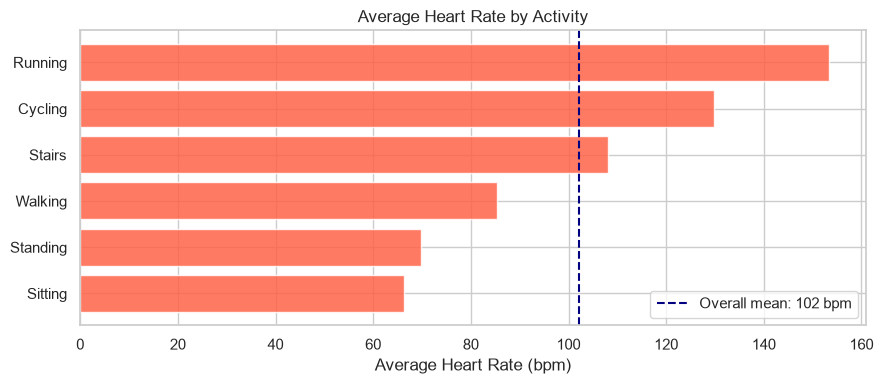

In [ ]:
# Visualise -- horizontal bar chart of average heart rate per activity
# (already written -- just run it)

hr_by_activity = df.groupby('activity')['heart_rate_bpm'].mean().sort_values()

plt.figure(figsize=(9, 4))
bars = plt.barh(hr_by_activity.index, hr_by_activity.values,
                color='tomato', edgecolor='white', alpha=0.85)
plt.xlabel('Average Heart Rate (bpm)')
plt.title('Average Heart Rate by Activity')
plt.axvline(hr_by_activity.mean(), color='navy', linestyle='--', linewidth=1.5,
            label=f'Overall mean: {hr_by_activity.mean():.0f} bpm')
plt.legend()
plt.tight_layout()
plt.show()

# Does the order of activities (low to high heart rate) make physical sense?
# YOUR ANSWER: Yes because you want to see what had the highest impact.

---
## Part 7 -- Making Better Features

Sometimes the raw sensor values are not the best input for a model.
We can **engineer new features** by combining existing ones.

### Example: Acceleration Magnitude

The wristband has three accelerometer axes: X, Y, Z.
If someone is running, their arm swings -- but the direction of the swing
depends on how the band is oriented on their wrist.

**Total acceleration** (magnitude) removes the orientation dependency:

```
acc_magnitude = sqrt(acc_x^2 + acc_y^2 + acc_z^2)
```

No matter how the watch is worn, a runner will have high magnitude.

### ✏️ YOUR TURN -- Create acc_magnitude

In [27]:
# Create acc_magnitude using the formula: sqrt(acc_x^2 + acc_y^2 + acc_z^2)
# Hint: use np.sqrt() and ** 2 for squaring

df['acc_magnitude'] = np.sqrt(df['acc_x']**2 + df['acc_y']**2+ df['acc_z']**2)

# Quick check -- print the first few values
print('First 5 acc_magnitude values:')
print(df['acc_magnitude'].head().round(3))
print(f'\nMin: {df["acc_magnitude"].min():.2f}')
print(f'Max: {df["acc_magnitude"].max():.2f}')
print(f'Mean: {df["acc_magnitude"].mean():.2f}')

First 5 acc_magnitude values:
0    9.898
1    9.986
2   10.014
3    9.856
4   10.324
Name: acc_magnitude, dtype: float64

Min: 0.89
Max: 20.80
Mean: 10.14


In [28]:
# Do the same for gyroscope magnitude
df['gyro_magnitude'] = np.sqrt(df['gyro_x']**2 + df['gyro_y']**2 + df['gyro_z']**2)

print('Both magnitude features created!')
print(df[['acc_magnitude','gyro_magnitude']].describe().round(3))

Both magnitude features created!
       acc_magnitude  gyro_magnitude
count       2100.000        2100.000
mean          10.141           1.163
std            1.905           1.219
min            0.890           0.010
25%            9.559           0.122
50%            9.859           0.886
75%           10.841           1.719
max           20.796           8.547


### 🔧 TWEAK IT -- Compare raw vs engineered

Run the chart. Then swap `'acc_x'` with `'acc_y'` or `'acc_z'` on the left
and observe: does the engineered `acc_magnitude` still look better?

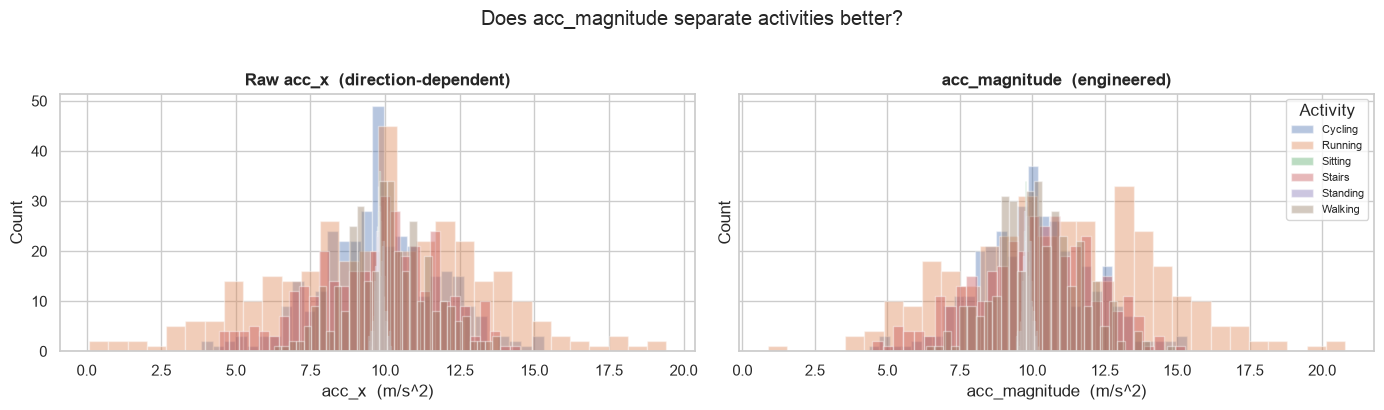

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for act in sorted(df['activity'].unique()):
    s = df[df['activity'] == act]
    ax1.hist(s['acc_z'], bins=30, alpha=0.4, label=act)       # <- TRY acc_y or acc_z
    ax2.hist(s['acc_magnitude'], bins=30, alpha=0.4, label=act)

ax1.set_title('Raw acc_x  (direction-dependent)', fontweight='bold')
ax1.set_xlabel('acc_x  (m/s^2)')
ax2.set_title('acc_magnitude  (engineered)', fontweight='bold')
ax2.set_xlabel('acc_magnitude  (m/s^2)')
for ax in [ax1, ax2]: ax.set_ylabel('Count')
ax2.legend(fontsize=8, title='Activity', loc='upper right')

plt.suptitle('Does acc_magnitude separate activities better?', y=1.02)
plt.tight_layout()
plt.show()

# YOUR ANSWER: Does acc_magnitude separate the activities better than raw acc_x? Why? Yes because it shows how the device moves in general and not in a given direction.

---
## You Did It! -- Exercise 1 Complete

Here is what you practised:

| Step | What you did |
|---|---|
| Load | `pd.read_csv()` to open a CSV file |
| Inspect | `.head()`, `.info()`, `.describe()` to understand the data |
| Check balance | `.value_counts()` to count samples per activity |
| Find missing | `.isnull().sum()` to find NaN values |
| Fix missing | `.fillna(median)` to impute with the column median |
| Visualise | Histograms to see how sensors separate activities |
| Group | `.groupby().mean()` to compare averages across activities |
| Engineer | `acc_magnitude` -- combining raw axes into one robust feature |

---

> **Up next:** Exercise 2 -- Correlations & Building a Classifier
> You will use the clean data you prepared here to train a model!

---
*Exercise 1 -- IoT ML Course | HAR Wearable Data*